<a href="https://colab.research.google.com/github/Emily-als/worklens-llm/blob/feature%2Fdata-exploration/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q datasets

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

In [5]:
dataset = load_dataset(
    "lallantop/glassdoor",
    split="train"
)

df = dataset.to_pandas()

archive (1).zip: reconstructing file:   0%|          |  0.00B / 88.0MB            

archive (1).zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/838566 [00:00<?, ? examples/s]

In [6]:
print("Dataset shape:", df.shape)
print("Number of companies:", df["firm"].nunique())

display(df.head())

Dataset shape: (838566, 18)
Number of companies: 428


,firm,date_review,job_title,current,location,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt,recommend,ceo_approv,outlook,headline,pros,cons
0,AFH-Wealth-Management,2015-04-05,,Current Employee,None,2,4.0,3.0,NaN,2.0,3.0,3.0,x,o,r,"Young colleagues, poor micro management",Very friendly and welcoming to new staff. Easy...,"Poor salaries, poor training and communication."
1,AFH-Wealth-Management,2015-12-11,Office Administrator,"Current Employee, more than 1 year","Bromsgrove, England, England",2,3.0,1.0,NaN,2.0,1.0,4.0,x,o,r,"Excellent staff, poor salary","Friendly, helpful and hard-working colleagues",Poor salary which doesn't improve much with pr...
2,AFH-Wealth-Management,2016-01-28,Office Administrator,"Current Employee, less than 1 year","Bromsgrove, England, England",1,1.0,1.0,NaN,1.0,1.0,1.0,x,o,x,"Low salary, bad micromanagement",Easy to get the job even without experience in...,"Very low salary, poor working conditions, very..."
3,AFH-Wealth-Management,2016-04-16,,Current Employee,None,5,2.0,3.0,NaN,2.0,2.0,3.0,x,o,r,Over promised under delivered,Nice staff to work with,No career progression and salary is poor
4,AFH-Wealth-Management,2016-04-23,Office Administrator,"Current Employee, more than 1 year","Bromsgrove, England, England",1,2.0,1.0,NaN,2.0,1.0,1.0,x,o,x,client reporting admin,"Easy to get the job, Nice colleagues.","Abysmal pay, around minimum wage. No actual tr..."


In [5]:
## Missing Values Analysis

In [7]:
text_columns = ["headline", "pros", "cons"]

target_columns = [
    "work_life_balance",
    "comp_benefits",
    "senior_mgmt"
]

relevant_columns = ["firm"] + text_columns + target_columns

missing = pd.DataFrame({
    "Missing Count": df[relevant_columns].isna().sum(),
    "Missing Percentage": (
        df[relevant_columns].isna().mean() * 100
    ).round(2)
})

display(missing)

,Missing Count,Missing Percentage
firm,0,0.00
headline,2590,0.31
pros,2,0.00
cons,13,0.00
work_life_balance,149894,17.88
comp_benefits,150082,17.90
senior_mgmt,155876,18.59


In [8]:
complete_ratings = df[target_columns].isin(
    [1, 2, 3, 4, 5]
).all(axis=1)

print("Complete valid ratings:", complete_ratings.sum())
print("Percentage:", round(complete_ratings.mean() * 100, 2))

Complete valid ratings: 679549
Percentage: 81.04


In [9]:
## Duplicate Reviews Analysis

In [10]:
full_duplicates = df.duplicated().sum()

text_duplicates = df.duplicated(
    subset=["headline", "pros", "cons"]
).sum()

print("Full duplicate rows:", full_duplicates)
print("Duplicate review texts:", text_duplicates)

print("Duplicate text percentage:",
      round(text_duplicates / len(df) * 100, 2))

Full duplicate rows: 33515
Duplicate review texts: 34979
Duplicate text percentage: 4.17


In [11]:
## Target Label Distribution

In [12]:
rating_mapping = {
    1: "Low",
    2: "Low",
    3: "Medium",
    4: "High",
    5: "High"
}

labels = df.loc[complete_ratings, target_columns].apply(
    lambda col: col.map(rating_mapping)
)

for col in target_columns:
    print(f"\n{col}:")
    display(labels[col].value_counts())
    display(labels[col].value_counts(normalize=True) * 100)


work_life_balance:


,count
work_life_balance,
High,340708
Low,171890
Medium,166951


,proportion
work_life_balance,
High,50.137371
Low,25.294718
Medium,24.567912



comp_benefits:


,count
comp_benefits,
High,338984
Medium,187644
Low,152921


,proportion
comp_benefits,
High,49.883673
Medium,27.613020
Low,22.503307



senior_mgmt:


,count
senior_mgmt,
High,302704
Low,205487
Medium,171358


,proportion
senior_mgmt,
High,44.544838
Low,30.238732
Medium,25.216430


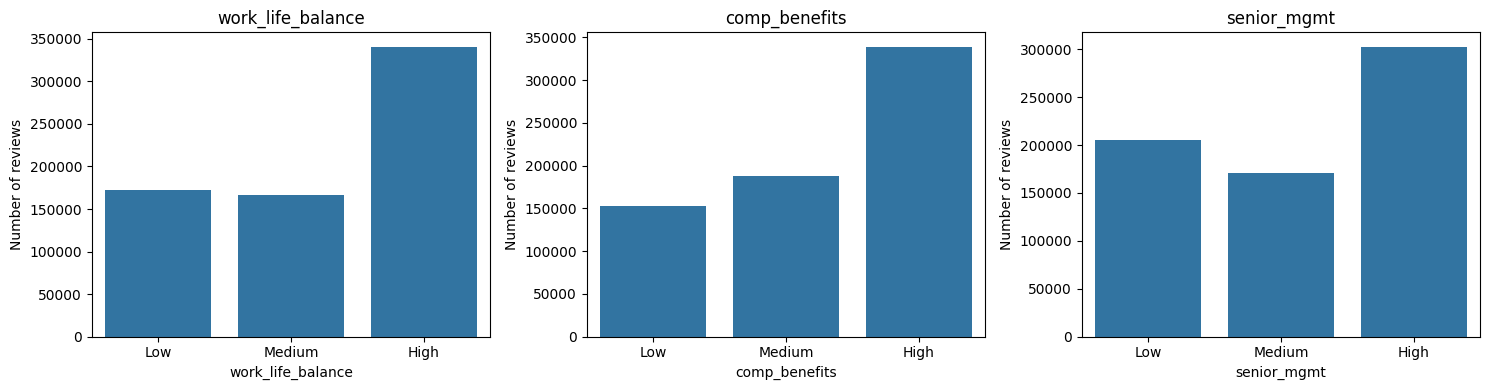

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for col, ax in zip(target_columns, axes):
    sns.countplot(
        data=labels,
        x=col,
        order=["Low", "Medium", "High"],
        ax=ax
    )
    ax.set_title(col)
    ax.set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()

In [14]:
## Mixed Reviews Analysis

In [15]:
mixed_mask = (
    labels.eq("High").any(axis=1) &
    labels.eq("Low").any(axis=1)
)

print("Mixed reviews:", mixed_mask.sum())

print("Mixed reviews percentage:",
      round(mixed_mask.mean() * 100, 2))

Mixed reviews: 153805
Mixed reviews percentage: 22.63


In [16]:
label_combinations = (
    labels.groupby(target_columns)
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Count")
)

label_combinations["Percentage"] = (
    label_combinations["Count"] / len(labels) * 100
).round(2)

display(label_combinations)

,work_life_balance,comp_benefits,senior_mgmt,Count,Percentage
0,High,High,High,170517,25.09
1,Low,Low,Low,60831,8.95
2,High,Medium,High,37045,5.45
3,High,High,Medium,34808,5.12
4,Medium,High,High,34390,5.06
5,Medium,Medium,Medium,29409,4.33
6,Low,Medium,Low,25501,3.75
7,High,Medium,Medium,24893,3.66
8,Medium,High,Medium,20863,3.07
9,Medium,Low,Low,19676,2.90


In [17]:
## Review Text Length Analysis

In [18]:
word_counts = df[text_columns].fillna("").apply(
    lambda col: col.str.count(r"\S+")
).sum(axis=1)

display(word_counts.describe(
    percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
))

print("Empty reviews:", (word_counts == 0).sum())

,0
count,838566.000000
mean,39.815313
std,51.685491
min,6.000000
25%,16.000000
50%,23.000000
75%,45.000000
90%,79.000000
95%,116.000000
99%,248.000000


Empty reviews: 0


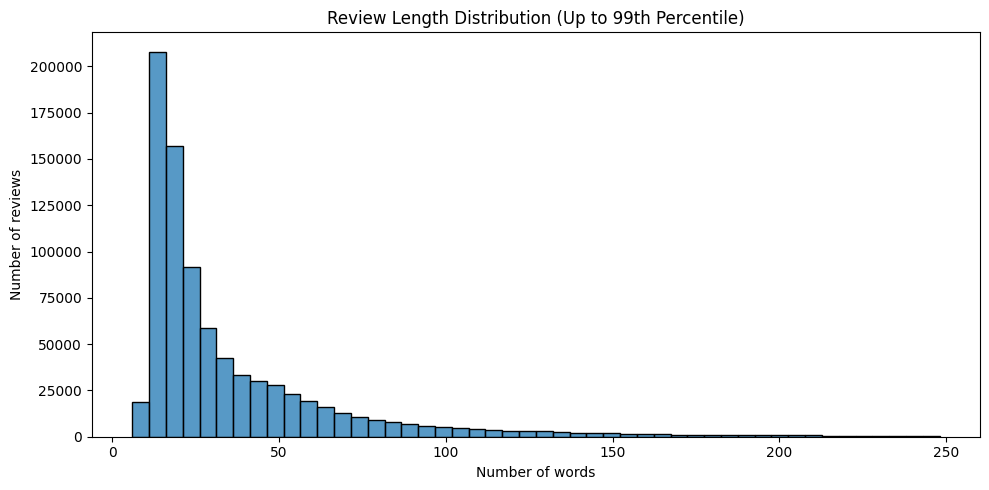

In [19]:
plt.figure(figsize=(10, 5))

p99 = word_counts.quantile(0.99)

sns.histplot(
    word_counts[word_counts <= p99],
    binwidth=5
)

plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.title("Review Length Distribution (Up to 99th Percentile)")
plt.tight_layout()
plt.show()

In [20]:
## Company Distribution Analysis

In [21]:
company_counts = df.loc[
    complete_ratings, "firm"
].value_counts()

print("Number of companies:", len(company_counts))

display(company_counts.describe())

display(company_counts.head(10))

print("Top 10 companies percentage:",
      round(company_counts.head(10).sum()
            / company_counts.sum() * 100, 2))

Number of companies: 428


,count
count,428.000000
mean,1587.731308
std,4776.386248
min,1.000000
25%,94.750000
50%,247.000000
75%,858.750000
max,50865.000000


,count
firm,
IBM,50865
Deloitte,37830
McDonald-s,34015
EY,27492
Oracle,26850
PwC,25996
Microsoft,22505
J-P-Morgan,20952
KPMG,19434


Top 10 companies percentage: 41.68


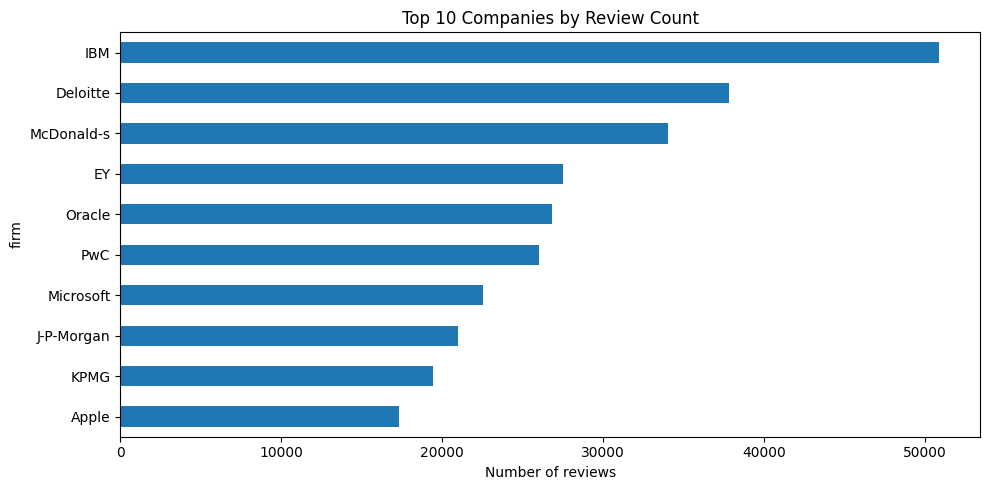

In [22]:
plt.figure(figsize=(10, 5))

company_counts.head(10).sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of reviews")
plt.title("Top 10 Companies by Review Count")
plt.tight_layout()
plt.show()